# chi2 map of a curve-of-growth fit -- validation on synthetic EWs

Goal: check `uncertainty.chi2_map` and `uncertainty.profile_interval` where the answer is known, before using them on 3C 273.

`fit_cog` gives errors from the curvature of $\chi^2$ at its minimum, i.e. it assumes $\chi^2$ is a parabola (an ellipse in the $(\log N, b)$ plane). The map computes $\chi^2$ on a grid instead:

- **joint regions** of $(\log N, b)$: $\Delta\chi^2 = 2.30$, 6.17, 11.8 (68, 95, 99.7 %);
- **interval of one parameter**: its *profile* (lowest $\Delta\chi^2$ over the other parameter) below 1 (68 %) or 3.84 (95 %).

When the fit is poor ($\chi^2_\mathrm{min}/\mathrm{dof} > 1$), $\chi^2$ is divided by $\chi^2_\mathrm{min}/\mathrm{dof}$ first (`Chi2Map.scale`).

Two cases: lines near the linear part (where the parabola holds) and saturated lines (where it does not). The EWs are exact (no noise), with errors given by hand, so the best fit is the truth and $\chi^2_\mathrm{min} = 0$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from spectral_diag.curve_of_growth import fit_cog, theoretical_ew
from spectral_diag.line_list import get_lines
from spectral_diag.plots import plot_chi2_map, plot_curve_of_growth, plot_profiles
from spectral_diag.uncertainty import ONE_PARAMETER_95, chi2_map, profile_interval


def exact_ews(lines, logN, b, relative_error):
    # {line name: (W, W_err)} of a cloud of known logN and b, no noise
    ews = {}
    for line in lines:
        width = theoretical_ew(line, logN, b)
        ews[line.name] = (width, relative_error * width)
    return ews


def print_intervals(cog_fit, result):
    # Covariance errors of fit_cog against the profile intervals of the map
    for parameter in ("logN", "b"):
        interval = profile_interval(result, parameter)
        wide = profile_interval(result, parameter, ONE_PARAMETER_95)
        print(
            f"{parameter:4s} fit {cog_fit[parameter]:.2f} +- {cog_fit[parameter + '_err']:.2f}   "
            f"map 68 %: [{interval.low:.2f}, {interval.high:.2f}]{edge_note(interval)}   "
            f"95 %: [{wide.low:.2f}, {wide.high:.2f}]{edge_note(wide)}"
        )


def edge_note(interval):
    # An end at the edge of the grid is only a limit
    if interval.low_at_grid_edge or interval.high_at_grid_edge:
        return " (grid edge: limit)"
    return ""

## 1. Near the linear part: the S II triplet (1250, 1253, 1259 Å) at $\log N = 14.5$, $b = 20$ km/s

EW errors of 10 %, so that the intervals span several grid steps (0.025 dex in $\log N$, 3 % in $b$). Here $\chi^2$ should be close to a parabola: the map and the covariance should agree.

scale 1.0
logN fit 14.50 +- 0.07   map 68 %: [14.44, 14.57]   95 %: [14.41, 14.64]
b    fit 20.00 +- 22.34   map 68 %: [9.66, 100.00] (grid edge: limit)   95 %: [6.54, 100.00] (grid edge: limit)


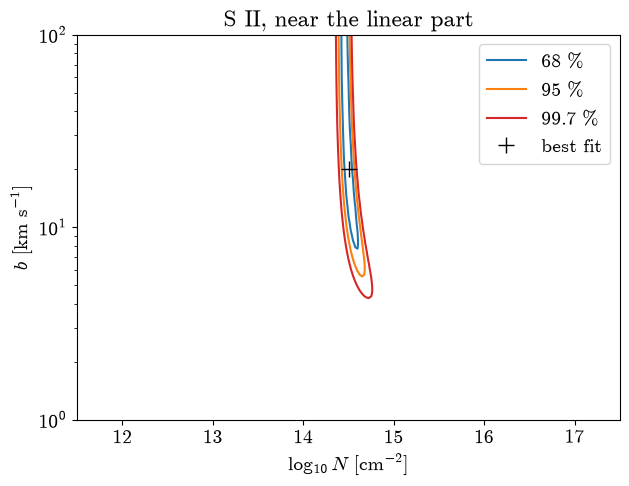

In [2]:
# The triplet of the COS range, as on 3C 273
sulphur_names = ["SII 1250.584", "SII 1253.811", "SII 1259.517"]
sulphur_lines = []
for line in get_lines("SII"):
    if line.name in sulphur_names:
        sulphur_lines.append(line)
sulphur_ews = exact_ews(sulphur_lines, 14.5, 20.0, 0.10)
sulphur_fit = fit_cog(sulphur_lines, sulphur_ews)
sulphur_map = chi2_map(sulphur_lines, sulphur_ews, sulphur_fit)
print(f"scale {sulphur_map.scale}")
print_intervals(sulphur_fit, sulphur_map)

fig, ax = plot_chi2_map(sulphur_map, "S II, near the linear part")
plt.show()

The 68 % interval of $\log N$ matches the covariance error. The joint region is a narrow band that is almost vertical at high $b$: there the lines are on the linear part, where $W$ does not depend on $b$, so $b$ is only bounded from below (its upper end is far, a limit rather than a measurement).

## 2. Saturated: Si II at $\log N = 15.5$, $b = 10$ km/s

The four Si II lines of the COS range (1190, 1193, 1260, 1304 Å), with 3 % errors, as on 3C 273.

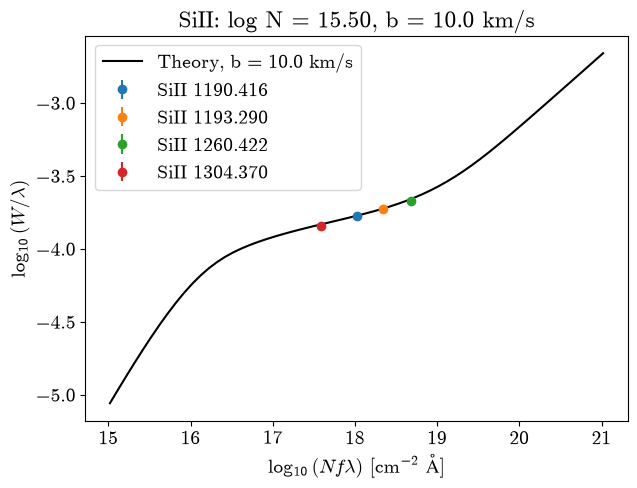

In [3]:
silicon_lines = get_lines("SiII")
silicon_names = ["SiII 1190.416", "SiII 1193.290", "SiII 1260.422", "SiII 1304.370"]
silicon_selected = []
for line in silicon_lines:
    if line.name in silicon_names:
        silicon_selected.append(line)
silicon_ews = exact_ews(silicon_selected, 15.5, 10.0, 0.03)
silicon_fit = fit_cog(silicon_selected, silicon_ews)

fig, ax = plot_curve_of_growth(silicon_selected, silicon_ews, silicon_fit)
plt.show()

scale 1.0
logN fit 15.50 +- 0.14   map 68 %: [15.27, 15.61]   95 %: [14.58, 15.69]
b    fit 10.00 +- 0.67   map 68 %: [9.45, 11.00]   95 %: [8.98, 14.73]


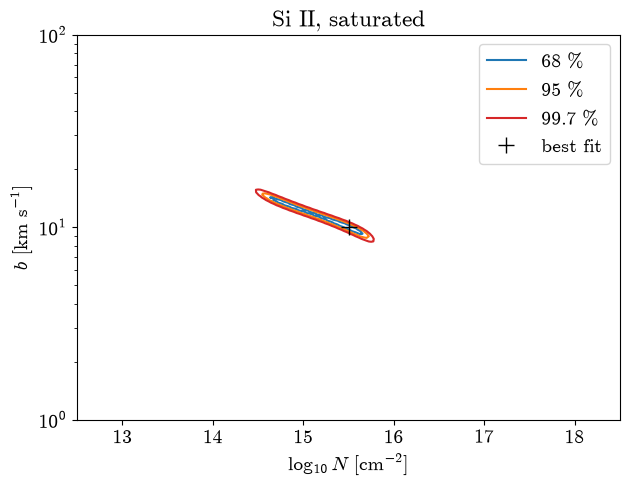

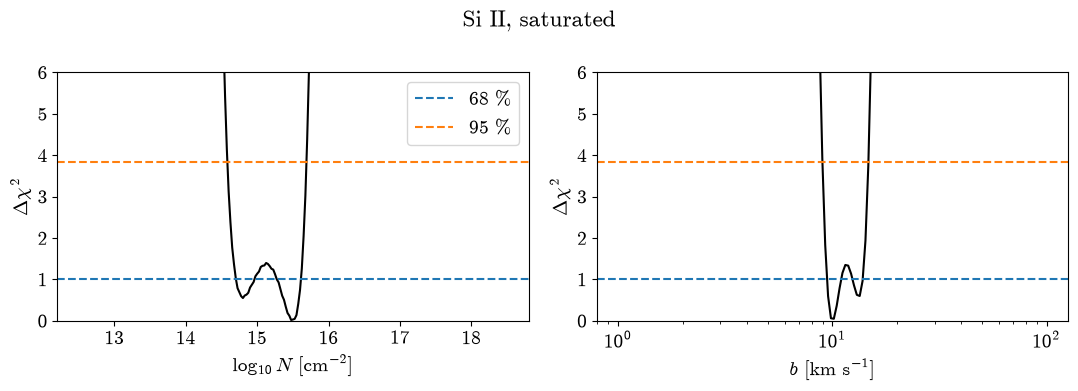

In [4]:
silicon_map = chi2_map(silicon_selected, silicon_ews, silicon_fit)
print(f"scale {silicon_map.scale}")
print_intervals(silicon_fit, silicon_map)

fig, ax = plot_chi2_map(silicon_map, "Si II, saturated")
plt.show()
fig, axes = plot_profiles(silicon_map, "Si II, saturated")
plt.show()

### 2.1 Is the grid fine enough?

The valley is narrower than one step of the $b$ grid (3 %), so the lowest grid point at a given $\log N$ can miss its bottom. `profile` refines it with a parabola through the lowest point and its two neighbours. We compare it with a 2000-point $b$ grid at a few $\log N$.


In [5]:
from spectral_diag.uncertainty import profile

DENSE_B_VALUES = np.geomspace(5.0, 30.0, 2000)

logN_grid, refined_profile = profile(silicon_map, "logN")
delta = silicon_map.delta_chi2()
for column in range(80, 140, 10):
    logN = logN_grid[column]
    dense_chi2 = []
    for b in DENSE_B_VALUES:
        chi2 = 0.0
        for line in silicon_selected:
            width, width_error = silicon_ews[line.name]
            chi2 += ((theoretical_ew(line, logN, b) - width) / width_error) ** 2
        dense_chi2.append(chi2)
    dense_delta = min(dense_chi2) - silicon_map.chi2_min
    print(
        f"logN {logN:.2f}: lowest grid point {np.min(delta[:, column]):.3f}, "
        f"refined {refined_profile[column]:.3f}, dense grid {dense_delta:.3f}"
    )


logN 14.50: lowest grid point 8.991, refined 8.941, dense grid 8.933


logN 14.75: lowest grid point 0.969, refined 0.690, dense grid 0.669


logN 15.00: lowest grid point 1.137, refined 1.136, dense grid 1.134


logN 15.25: lowest grid point 1.160, refined 1.123, dense grid 1.132


logN 15.50: lowest grid point 0.611, refined 0.029, dense grid 0.000


logN 15.75: lowest grid point 8.313, refined 8.231, dense grid 8.217


The refined profile agrees with the dense grid to a few hundredths, while the lowest grid point alone can be off by more than 0.5.


All four lines sit on the flat part of the curve, where $W$ grows only as $b\sqrt{\ln \tau_0}$: a larger $N$ can be traded for a smaller $b$. The joint region is a long diagonal valley, not an ellipse. Along it the profile of $\log N$ is almost flat, with a second local minimum near 14.75 (section 2.1 shows it is real, not a grid effect): even with exact EWs at 3 %, the 95 % interval spans 14.6–15.7, against $\pm 0.14$ from the covariance. The map gives the honest range; the covariance error only describes the bottom of the valley.

## 3. Rescaling a poor fit

If the measured EWs scatter more than their errors allow, $\chi^2_\mathrm{min}/\mathrm{dof} > 1$. Dividing $\chi^2$ by that factor widens every interval by its square root. We move one S II EW by 4 errors.

In [6]:
from dataclasses import replace

perturbed_ews = dict(sulphur_ews)
first_name = sulphur_lines[0].name
width, width_error = perturbed_ews[first_name]
perturbed_ews[first_name] = (width + 4 * width_error, width_error)

perturbed_fit = fit_cog(sulphur_lines, perturbed_ews)
perturbed_map = chi2_map(sulphur_lines, perturbed_ews, perturbed_fit)
print(f"chi2 {perturbed_fit['chi2']:.1f} for {perturbed_fit['dof']} dof, scale {perturbed_map.scale:.1f}")

raw_map = replace(perturbed_map, scale=1.0)
for name, result in (("raw", raw_map), ("rescaled", perturbed_map)):
    interval = profile_interval(result, "logN")
    print(f"{name:9s} logN 68 %: [{interval.low:.3f}, {interval.high:.3f}]")

chi2 1.6 for 1 dof, scale 1.6
raw       logN 68 %: [14.681, 14.845]
rescaled  logN 68 %: [14.662, 14.875]


The rescaled interval is wider by about $\sqrt{\mathrm{scale}}$.

## Summary

- Where $\chi^2$ is a parabola (lines near the linear part), the map gives the same 68 % interval as the covariance of `fit_cog`: the method is right.
- For saturated lines, the joint region is a long valley along which $N$ and $b$ trade against each other; the map shows its real extent.
- A poor fit is handled by rescaling $\chi^2$ by $\chi^2_\mathrm{min}/\mathrm{dof}$.
- Not checked here: the coverage of the intervals over many noisy realisations (each map takes ~15 s).